# Data Pipeline - Hotel Booking Cancellation Prediction

This notebook rebuilds the cleaning pipeline from the Stage 1 `02_data_readiness.ipynb` notebook, with revisions made in response to the Stage 1 feedback. The output of this revised pipeline is a cleaned hotel booking dataset stored in `data/hotel_bookings_cleaned.csv`, which will be used for modelling in `02_modelling_evaluation.ipynb`.

**Stakeholder:** A hotel revenue manager who needs to decide which booking segments, such as market segments, distribution channels or customer types, should be prioritised for pre-arrival monitoring and revised room-allocation or promotion planning.

**Research question:** Which characteristics available during the pre-arrival period are associated with cancellation or non-arrival, and which booking segments should a hotel revenue manager prioritise for monitoring before scheduled arrival?

**Target outcome:** The target is `is_canceled`. A value of 1 represents a cancellation or non-arrival, including records with a final status of `Canceled` or `No-Show`. A value of 0 represents bookings with a final status of `Check-Out`.

**Decision-time point:** The intended decision occurs after booking confirmation and during the pre-arrival period, before the final reservation outcome is used for action.

In [1]:
# import libraries
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats.contingency import association


# set up display options
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

# set random seed for reproducibility
RANDOM_SEED = 5310
np.random.seed(RANDOM_SEED)

# set up paths
DATA_DIR = Path('data')
RAW_PATH = DATA_DIR / 'hotel_bookings.csv'
OUTPUT_PATH = DATA_DIR / 'hotel_bookings_cleaned.csv'


In [2]:
# create cleaning log to track changes made to the dataset
cleaning_log = []

def log_preprocessing(issue, evidence, justification, action, before, after):
    cleaning_log.append({
        'issue': issue,
        'evidence': evidence,
        'action': action,
        'justification': justification,
        'before': before,
        'after': after
    })

## 1. Load Data and Initial Inspection

In [3]:
# load the raw dataset
hotel_df = pd.read_csv(RAW_PATH)

# keep a copy of the original dataset to ensure immutability of the raw data
hotel_df_raw = hotel_df.copy()

print("Initial dataset shape:", hotel_df.shape)

Initial dataset shape: (119987, 32)


## 2. Data Preprocessing and Cleaning

### 2.1 Missingness

#### 2.1.1 Missing Values Representation

`convert_dtypes()` is applied to ensure consistent representation of missing values across all columns.

In [4]:
def summarise_dtypes(df):
    counts = df.dtypes.value_counts()
    lines = [f'{n} {t}' for t, n in counts.items()]
    lines.append(f'shape of the dataset: {df.shape}')
    return '\n'.join(lines)

# start fresh with a copy of the raw dataset to ensure immutability of the raw data
hotel_df = hotel_df_raw.copy()
before_dtypes = summarise_dtypes(hotel_df)
# ensure missing value representation is consistent and integer columns are stored as Int64 instead of float64
hotel_df = hotel_df.convert_dtypes()
after_dtypes = summarise_dtypes(hotel_df)

log_preprocessing(
    issue='Missing-value representation is inconsistent and integer columns are stored as float64',
    evidence=f'Raw dtypes:\n{before_dtypes}',
    action='Converted all columns to pandas nullable dtypes (Int64/Float64/string) so every missing value is represented consistently as pandas.NA.',
    justification='convert_dtypes() infers nullable Int64/Float64/string dtypes from the actual values, recovering integer columns pd.read_csv() only cast to float64 because they contain missing values, and unifying every missing value to pandas.NA.',
    before=before_dtypes,
    after=after_dtypes,
)

#### 2.1.2 Missing Values Summary

In [5]:
# show the missing values columns and the percentage
missing_before = hotel_df.isna().sum()
missing_before = missing_before[missing_before > 0]
missing_before = pd.DataFrame({
    'missing_count': missing_before,
    'missing_percentage (%)': (missing_before / len(hotel_df) * 100).round(2)
})
# order the columns by missing percentage in descending order
missing_before = missing_before.sort_values(by='missing_percentage (%)', ascending=False)
missing_before

,missing_count,missing_percentage (%)
company,113162,94.31
agent,16541,13.79
country,628,0.52
children,182,0.15
distribution_channel,164,0.14
customer_type,154,0.13
meal,138,0.12
market_segment,129,0.11


8 of the 32 columns have any missing values, and the missingness is highly skewed toward a few columns, namely `company` and `agent`. The handling remains the same as in Stage 1, with changes made to the `country` in response to Stage 1 feedback. 

#### 2.1.3 Missing Values - Company & Agent

In [6]:
def summarise_missing(df, columns):
    lines = [f'{int(df[col].isna().sum())} missing {col}' for col in columns]
    lines.append(f'shape of the dataset: {df.shape}')
    return '\n'.join(lines)

# implement new features
before_summary = summarise_missing(hotel_df, ['agent', 'company'])

# impute missing values for company and agent with a placeholder value (e.g., 0) to indicate "no company/agent involved"
hotel_df['company'] = hotel_df['company'].fillna(0).astype('Int64')
hotel_df['agent'] = hotel_df['agent'].fillna(0).astype('Int64')

after_summary = summarise_missing(hotel_df, ['agent', 'company'])

# log the preprocessing steps for company and agent
log_preprocessing(
    issue='agent and company are missing for a large share of rows (agent 13.79%, company 94.31%); a missing value most plausibly means "no agent/company was involved in this booking" rather than an unrecorded value.',
    evidence=f'Before:\n{before_summary}\nNeither column contains a 0, negative, or non-integer value that could already represent "no agent/company" (agent range 1-535, company range 6-543).',
    action='Imputed the missing company and agent values with 0 to represent "not involved".',
    justification='Treating missing agent/company as a genuine "not involved" category preserves its cancellation-risk signal rather than discarding it via row deletion or mode imputation. 0 is a safe placeholder since it does not collide with any real agent/company ID.',
    before=before_summary,
    after=after_summary,
)

#### 2.1.4 Missing Values - Country

In [7]:
other_missing_cols = missing_before.index.difference(['company', 'agent']).tolist()

# remove country from other missing columns
other_missing_cols.remove('country')

# value counts for the country
hotel_df['country'].value_counts(dropna=False).sort_index()


country
ABW       2
AGO     369
AIA       1
ALB      12
AND       7
       ... 
VNM       8
ZAF      80
ZMB       2
ZWE       4
<NA>    628
Name: count, Length: 178, dtype: Int64

In [8]:
# check the nature of the 628 missing-country rows 
na_country = hotel_df[hotel_df['country'].isna()]

# compare the features with missing country rows to the entire dataset to see whether the missingness correlates with any other features, especially the outcome variable `is_canceled`
comparison = pd.concat(
    {
        'non-missing_country': hotel_df[hotel_df['country'].notna()].describe(include='all').T,
        'missing_country': na_country.describe(include='all').T,
    },
    axis=1,
).swaplevel(axis=1)

# put the two groups side by side for each key statistic
comparison = comparison[['mean', '50%', 'std']]

comparison


mean                                 50%                                 std                
                               non-missing_country missing_country non-missing_country missing_country non-missing_country missing_country
hotel                                          NaN             NaN                 NaN             NaN                 NaN             NaN
is_canceled                                0.37135        0.197452                 0.0             0.0            0.483168        0.398394
lead_time                               106.401227       49.894904                70.0             6.0          114.849754       85.172543
arrival_date_year                      2016.157525     2015.952229              2016.0          2016.0            0.707517        0.687745
arrival_date_month                             NaN             NaN                 NaN             NaN                 NaN             NaN
arrival_date_week_number                 27.169665       26.624204                28.0            27.0           13.590431       16.164392
arrival_date_day_of_month                15.802403       15.227707                16.0            15.0            8.781596        8.906965
stays_in_weekend_nights                   0.928954        0.676752                 1.0             0.0             0.99617        1.357465
stays_in_week_nights                      2.501738        2.152866                 2.0             1.0            1.899755        3.046509
adults                                    1.858276        1.477707                 2.0             1.0            0.578181        0.554362
children                                  0.104289        0.035144                 0.0             0.0            0.399332        0.208717
babies                                    0.007968        0.006369                 0.0             0.0            0.097447        0.097615
meal                                           NaN             NaN                 NaN             NaN                 NaN             NaN
country                                        NaN             NaN                 NaN             NaN                 NaN             NaN
market_segment                                 NaN             NaN                 NaN             NaN                 NaN             NaN
distribution_channel                           NaN             NaN                 NaN             NaN                 NaN             NaN
is_repeated_guest                         0.032038        0.011146                 0.0             0.0            0.176101        0.105071
previous_cancellations                    0.086805        0.117834                 0.0             0.0            0.842194        0.885179
previous_bookings_not_canceled            0.131578        1.149682                 0.0             0.0            1.483717        2.821067
reserved_room_type                             NaN             NaN                 NaN             NaN                 NaN             NaN
assigned_room_type                             NaN             NaN                 NaN             NaN                 NaN             NaN
booking_changes                           0.221165        0.203822                 0.0             0.0            0.652617        0.532681
deposit_type                                   NaN             NaN                 NaN             NaN                 NaN             NaN
agent                                     74.86802       58.746815                 9.0             0.0          107.160793      103.323131
company                                  10.558843       52.353503                 0.0             0.0           53.503194      103.736735
days_in_waiting_list                      2.329653        0.332803                 0.0             0.0           17.624082         3.88623
customer_type                                  NaN             NaN                 NaN             NaN                 NaN             NaN
adr            

A chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `country`.

In [9]:
from scipy.stats import chi2_contingency

is_na_country = hotel_df['country'].isna()

# does missingness in country relate to the outcome?
cancel_na_country = hotel_df.loc[is_na_country, 'is_canceled'].mean() * 100
cancel_present_country = hotel_df.loc[~is_na_country, 'is_canceled'].mean() * 100
chi2_country, p_country, _, _ = chi2_contingency(pd.crosstab(is_na_country, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na_country:.2f}% missing vs. {cancel_present_country:.2f}% present')
print(f'Chi-squared = {chi2_country:.2f}, p = {p_country:.1e}')


Cancellation rate: 19.75% missing vs. 37.14% present
Chi-squared = 80.26, p = 3.3e-19


**Interpretation:** rows with missing `country` cancel at 19.7% vs. 37.1% for the rest. The chi-squared test rejects independence (chi-squared = 80.26, p < 0.001): a gap this large is very unlikely to be due to chance, so missingness in `country` is associated with the outcome and is **not missing completely at random (MCAR)**.

The comparison table shows the same group differs on other features too: shorter lead times (median 6 vs. 70 days), lower prices (median `adr` 54 vs. 95), fewer adults, and more company-linked rather than agent-linked bookings. This looks like a distinct segment of short-notice bookings, possibly direct or corporate bookings where nationality was not captured, although the table alone cannot confirm the cause.

**Decision:** recode missing values to an explicit `Unknown` category. Dropping the rows would remove a low-cancellation segment and bias the data, and mode imputation would assign a nationality the data cannot support.

In [10]:
# recode missing country values to an explicit "Unknown" category, backed by
# the checks above -- not mode imputation, not dropping rows
before_summary_country = summarise_missing(hotel_df, ['country'])

hotel_df['country'] = hotel_df['country'].fillna('Unknown')

after_summary_country = summarise_missing(hotel_df, ['country'])

log_preprocessing(
    issue='Missing values in country cluster around a specific booking profile and a much lower cancellation rate, rather than being spread evenly.',
    evidence=f'The 628 NA-country rows are mostly Resort Hotel, Corporate, and Direct bookings rather than the travel-agent channels that dominate the rest of the dataset. Cancellation rate {cancel_na_country:.2f}% missing vs. {cancel_present_country:.2f}% present (chi-squared = {chi2_country:.2f}, p = {p_country:.1e}).',
    action='Recoded the missing country values to an explicit "Unknown" category.',
    justification='Since the missingness itself carries a real signal tied to booking channel and cancellation risk, mode-imputing (which would fabricate a nationality) or dropping the rows (which would discard that low-cancellation segment) would both distort the dataset. Keeping it as an explicit category preserves the pattern as a usable feature, at negligible cost given the small missingness rate (0.52%).',
    before=before_summary_country,
    after=after_summary_country,
)

#### 2.1.5 Missing Values - Children

In [11]:
other_missing_cols.remove('children')

# unique values for children
children_unique = hotel_df['children'].unique()
print(children_unique)
print()
print(hotel_df['children'].value_counts(dropna=False).sort_index())

<IntegerArray>
[0, 1, 2, <NA>, 3, 10]
Length: 6, dtype: Int64

children
0       111181
1         4881
2         3666
3           76
10           1
<NA>       182
Name: count, dtype: Int64


The true value of `children` cannot be recovered for these 182 rows. Dropping them is only safe if the missingness is unrelated to the outcome. A chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `children` value.

In [12]:
is_na_children = hotel_df['children'].isna()

# does missingness in children relate to the outcome?
cancel_na = hotel_df.loc[is_na_children, 'is_canceled'].mean() * 100
cancel_present = hotel_df.loc[~is_na_children, 'is_canceled'].mean() * 100
chi2, p_children, _, _ = chi2_contingency(pd.crosstab(is_na_children, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na:.2f}% missing vs. {cancel_present:.2f}% present')
print(f'Chi-squared = {chi2:.2f}, p = {p_children:.2f}')


Cancellation rate: 35.16% missing vs. 37.05% present
Chi-squared = 0.20, p = 0.65


**Interpretation:** rows with missing `children` cancel at 35.2% vs. 37.0% for the rest, and the difference is not significant (chi-squared p = 0.65). The missingness shows no link to the outcome, so dropping these rows should not bias the data. Imputing 0 would assume the booking had no children, which the data cannot confirm.

**Decision:** drop the 182 rows (0.15% of the data).

In [13]:
# drop rows with missing children, backed by the chi-squared check above
before_summary_children = summarise_missing(hotel_df, ['children'])

hotel_df = hotel_df.dropna(subset=['children']).reset_index(drop=True)

after_summary_children = summarise_missing(hotel_df, ['children'])

log_preprocessing(
    issue='children is missing for 182 rows (0.15%) and the true value cannot be recovered.',
    evidence=f'Cancellation rate {cancel_na:.2f}% missing vs. {cancel_present:.2f}% present (chi-squared = {chi2:.2f}, p = {p_children:.2f}).',
    action='Dropped the 182 rows with missing children.',
    justification='The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Imputing 0 would assume the booking had no children, which the data cannot confirm. The cost is 0.15% of rows.',
    before=before_summary_children,
    after=after_summary_children,
)


#### 2.1.6 Missing Values - Customer Type

In [14]:
hotel_df['customer_type'].value_counts(dropna=False).sort_index()

customer_type
Contract             4082
GROUP                   1
Group                 576
Transient           89676
Transient             137
Transient-Party     25123
Transient-Party        49
contract                7
<NA>                  154
Name: count, dtype: Int64

The true value of `customer_type` cannot be recovered for these 154 rows. As with `children`, dropping them is only safe if the missingness is unrelated to the outcome. A chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `customer_type`.

In [15]:
is_na_customer_type = hotel_df['customer_type'].isna()

# does missingness in customer_type relate to the outcome?
cancel_na_ct = hotel_df.loc[is_na_customer_type, 'is_canceled'].mean() * 100
cancel_present_ct = hotel_df.loc[~is_na_customer_type, 'is_canceled'].mean() * 100
chi2_ct, p_customer_type, _, _ = chi2_contingency(pd.crosstab(is_na_customer_type, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na_ct:.2f}% missing vs. {cancel_present_ct:.2f}% present')
print(f'Chi-squared = {chi2_ct:.2f}, p = {p_customer_type:.2f}')


Cancellation rate: 38.96% missing vs. 37.04% present
Chi-squared = 0.17, p = 0.68


**Interpretation:** rows with missing `customer_type` cancel at 38.96% vs. 37.04% for the rest, and the difference is not significant (chi-squared p = 0.68). The missingness shows no link to the outcome, so dropping these rows should not bias the data. Imputing the mode (`Transient`) or adding an `Unknown` category would assign a customer type, or create a category, that the data cannot support.

**Decision:** drop the 154 rows (0.13% of the data).

In [16]:
# drop rows with missing customer_type, backed by the chi-squared check above
before_summary_customer_type = summarise_missing(hotel_df, ['customer_type'])

hotel_df = hotel_df.dropna(subset=['customer_type']).reset_index(drop=True)

after_summary_customer_type = summarise_missing(hotel_df, ['customer_type'])

log_preprocessing(
    issue='customer_type is missing for 154 rows (0.13%) and the true value cannot be recovered.',
    evidence=f'Cancellation rate {cancel_na_ct:.2f}% missing vs. {cancel_present_ct:.2f}% present (chi-squared = {chi2_ct:.2f}, p = {p_customer_type:.2f}).',
    action='Dropped the 154 rows with missing customer_type.',
    justification='The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Mode imputation would assign a customer type the data cannot confirm, and an "Unknown" category would preserve no signal. The cost is 0.13% of rows.',
    before=before_summary_customer_type,
    after=after_summary_customer_type,
)


#### 2.1.7 Missing Values - Distribution Channel

In [17]:
hotel_df['distribution_channel'].value_counts(dropna=False).sort_index()

distribution_channel
Corporate      6687
Corporate         9
Direct        14637
Direct           29
GDS             193
TA/TO         97774
TA/TO           156
Undefined         1
gds               1
<NA>            164
Name: count, dtype: Int64

The true value of `distribution_channel` cannot be recovered for these 164 rows. As with `children` and `customer_type`, a chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `distribution_channel`.

In [18]:
is_na_distribution_channel = hotel_df['distribution_channel'].isna()

# does missingness in distribution_channel relate to the outcome?
cancel_na_dc = hotel_df.loc[is_na_distribution_channel, 'is_canceled'].mean() * 100
cancel_present_dc = hotel_df.loc[~is_na_distribution_channel, 'is_canceled'].mean() * 100
chi2_dc, p_distribution_channel, _, _ = chi2_contingency(pd.crosstab(is_na_distribution_channel, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na_dc:.2f}% missing vs. {cancel_present_dc:.2f}% present')
print(f'Chi-squared = {chi2_dc:.2f}, p = {p_distribution_channel:.2f}')


Cancellation rate: 41.46% missing vs. 37.04% present
Chi-squared = 1.19, p = 0.27


**Interpretation:** rows with missing `distribution_channel` cancel at 41.5% vs. 37.0% for the rest, but the difference is not significant (chi-squared = 1.19, p = 0.27). A gap this size could easily arise by chance in 164 rows, so there is no evidence that the missingness is linked to the outcome, and dropping these rows should not bias the data. Imputing the mode (`TA/TO`) or adding an `Unknown` category would assign a channel, or create a category, that the data cannot support.

**Decision:** drop the 164 rows (0.14% of the data).

In [19]:
# drop rows with missing distribution_channel, backed by the chi-squared check above
before_summary_distribution_channel = summarise_missing(hotel_df, ['distribution_channel'])

hotel_df = hotel_df.dropna(subset=['distribution_channel']).reset_index(drop=True)

after_summary_distribution_channel = summarise_missing(hotel_df, ['distribution_channel'])

log_preprocessing(
    issue='distribution_channel is missing for 164 rows (0.14%) and the true value cannot be recovered.',
    evidence=f'Cancellation rate {cancel_na_dc:.2f}% missing vs. {cancel_present_dc:.2f}% present (chi-squared = {chi2_dc:.2f}, p = {p_distribution_channel:.2f}).',
    action='Dropped the 164 rows with missing distribution_channel.',
    justification='The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Mode imputation would assign a channel the data cannot confirm, and an "Unknown" category would preserve no signal. The cost is 0.14% of rows.',
    before=before_summary_distribution_channel,
    after=after_summary_distribution_channel,
)


#### 2.1.8 Missing Values - Market Segment

In [20]:
hotel_df['market_segment'].value_counts(dropna=False).sort_index()

market_segment
Aviation           239
COMPLEMENTARY        3
Complementary      745
Corporate         5280
Corporate           24
Direc               20
Direct           12585
Groups           19780
Offline TA/TO    24156
Online TA        56448
Undefined            1
groups              32
offline ta/to       45
<NA>               129
Name: count, dtype: Int64

The true value of `market_segment` cannot be recovered for these 129 rows. As with `children`, `customer_type` and `distribution_channel`, a chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `market_segment`.

In [21]:
is_na_market_segment = hotel_df['market_segment'].isna()

# does missingness in market_segment relate to the outcome?
cancel_na_ms = hotel_df.loc[is_na_market_segment, 'is_canceled'].mean() * 100
cancel_present_ms = hotel_df.loc[~is_na_market_segment, 'is_canceled'].mean() * 100
chi2_ms, p_market_segment, _, _ = chi2_contingency(pd.crosstab(is_na_market_segment, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na_ms:.2f}% missing vs. {cancel_present_ms:.2f}% present')
print(f'Chi-squared = {chi2_ms:.2f}, p = {p_market_segment:.2f}')


Cancellation rate: 43.41% missing vs. 37.03% present
Chi-squared = 1.98, p = 0.16


**Interpretation:** rows with missing `market_segment` cancel at 43.4% vs. 37.0% for the rest, but the difference is not significant (chi-squared = 1.98, p = 0.16). A gap this size could easily arise by chance in 129 rows, so there is no evidence that the missingness is linked to the outcome, and dropping these rows should not bias the data. Imputing the mode (`Online TA`) or adding an `Unknown` category would assign a segment, or create a category, that the data cannot support.

**Decision:** drop the 129 rows (0.11% of the data).

In [22]:
# drop rows with missing market_segment, backed by the chi-squared check above
before_summary_market_segment = summarise_missing(hotel_df, ['market_segment'])

hotel_df = hotel_df.dropna(subset=['market_segment']).reset_index(drop=True)

after_summary_market_segment = summarise_missing(hotel_df, ['market_segment'])

log_preprocessing(
    issue='market_segment is missing for 129 rows (0.11%) and the true value cannot be recovered.',
    evidence=f'Cancellation rate {cancel_na_ms:.2f}% missing vs. {cancel_present_ms:.2f}% present (chi-squared = {chi2_ms:.2f}, p = {p_market_segment:.2f}).',
    action='Dropped the 129 rows with missing market_segment.',
    justification='The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Mode imputation would assign a segment the data cannot confirm, and an "Unknown" category would preserve no signal. The cost is 0.11% of rows.',
    before=before_summary_market_segment,
    after=after_summary_market_segment,
)


#### 2.1.9 Missing Values - Meal

In [23]:
hotel_df['meal'].value_counts(dropna=False).sort_index()

meal
BB            92022
FB              795
FB                3
HB            14401
HB               30
SC            10628
SC               14
Undefined      1164
Undefined         4
bb              159
<NA>            138
Name: count, dtype: Int64

The true value of `meal` cannot be recovered for these 138 rows. As with the other low-missingness columns, a chi-squared test of independence checks whether the cancellation rate differs between rows with and without a recorded `meal`.

In [24]:
is_na_meal = hotel_df['meal'].isna()

# does missingness in meal relate to the outcome?
cancel_na_meal = hotel_df.loc[is_na_meal, 'is_canceled'].mean() * 100
cancel_present_meal = hotel_df.loc[~is_na_meal, 'is_canceled'].mean() * 100
chi2_meal, p_meal, _, _ = chi2_contingency(pd.crosstab(is_na_meal, hotel_df['is_canceled']))

print(f'Cancellation rate: {cancel_na_meal:.2f}% missing vs. {cancel_present_meal:.2f}% present')
print(f'Chi-squared = {chi2_meal:.2f}, p = {p_meal:.2f}')


Cancellation rate: 41.30% missing vs. 37.03% present
Chi-squared = 0.91, p = 0.34


**Interpretation:** rows with missing `meal` cancel at 41.3% vs. 37.0% for the rest, but the difference is not significant (chi-squared = 0.91, p = 0.34). A gap this size could easily arise by chance in 138 rows, so there is no evidence that the missingness is linked to the outcome, and dropping these rows should not bias the data. Folding them into the existing `Undefined` category would assume a missing value means the same as `Undefined`, which the data cannot confirm.

**Decision:** drop the 138 rows (0.12% of the data).

In [25]:
# drop rows with missing meal, backed by the chi-squared check above
before_summary_meal = summarise_missing(hotel_df, ['meal'])

hotel_df = hotel_df.dropna(subset=['meal']).reset_index(drop=True)

after_summary_meal = summarise_missing(hotel_df, ['meal'])

log_preprocessing(
    issue='meal is missing for 138 rows (0.12%) and the true value cannot be recovered.',
    evidence=f'Cancellation rate {cancel_na_meal:.2f}% missing vs. {cancel_present_meal:.2f}% present (chi-squared = {chi2_meal:.2f}, p = {p_meal:.2f}).',
    action='Dropped the 138 rows with missing meal.',
    justification='The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Folding them into the existing "Undefined" category would assume a missing value means the same as "Undefined", which the data cannot confirm. The cost is 0.12% of rows.',
    before=before_summary_meal,
    after=after_summary_meal,
)


#### 2.1.10 Missing Values - Summary

| Column | Missing rows (%) | Chi-squared p (missing vs. cancellation) | Treatment | Section |
|---|---|---|---|---|
| `company` | 113,162 (94.31%) | not tested | Imputed 0 = no company involved | 2.1.3 |
| `agent` | 16,541 (13.79%) | not tested | Imputed 0 = no agent involved | 2.1.3 |
| `country` | 628 (0.52%) | < 0.001 | Recoded to explicit `Unknown` category | 2.1.4 |
| `children` | 182 (0.15%) | 0.65 | Rows dropped | 2.1.5 |
| `customer_type` | 154 (0.13%) | 0.68 | Rows dropped | 2.1.6 |
| `distribution_channel` | 164 (0.14%) | 0.27 | Rows dropped | 2.1.7 |
| `market_segment` | 129 (0.11%) | 0.16 | Rows dropped | 2.1.8 |
| `meal` | 138 (0.12%) | 0.34 | Rows dropped | 2.1.9 |

`agent` and `company` are not tested because a missing value is treated as a meaningful "not involved" value rather than an unrecorded one. For the other columns, the rule is the same throughout: missingness significantly linked to cancellation is kept as its own category (`country` only); otherwise the rows are dropped. In total, 767 rows (0.64%) are dropped for missing values.

### 2.2 Duplicates

In [26]:
# check for duplicates
before_duplicates_count = hotel_df.duplicated().sum()
if before_duplicates_count > 0:
    print(f"Found {before_duplicates_count} duplicate rows, which is {before_duplicates_count / len(hotel_df) * 100:.2f}% of the dataset.")

Found 31322 duplicate rows, which is 26.27% of the dataset.


In [27]:
# are the duplicate groups uniformly small (consistent with accidental re-export) or do some run large (which would suggest something else, e.g. a group block)?
print(f"rows involved in duplicate groups: {int(hotel_df.duplicated(keep=False).sum())}")
print(f"number of distinct duplicate groups: {hotel_df[hotel_df.duplicated(keep=False)].groupby(hotel_df.columns.tolist()).ngroups}")

rows involved in duplicate groups: 39584
number of distinct duplicate groups: 8262


In [28]:
print("cardinality of a few fields every duplicate also matches on:")
for col in ['reservation_status_date', 'adr', 'lead_time']:
    print(f"  {col}: {hotel_df[col].nunique()} unique values")

cardinality of a few fields every duplicate also matches on:
  reservation_status_date: 1681 unique values
  adr: 9096 unique values
  lead_time: 731 unique values


In [29]:
# check whether the duplicate rows have a different cancellation rate than the overall dataset
rate_dup = hotel_df.loc[hotel_df.duplicated(keep=False), 'is_canceled'].mean() * 100
rate_overall = hotel_df['is_canceled'].mean() * 100
print(f"cancellation rate: {rate_dup:.2f}% among duplicate-involved rows vs. {rate_overall:.2f}% overall")

cancellation rate: 57.92% among duplicate-involved rows vs. 37.03% overall


In [30]:
# check whether the duplicate rows are concentrated in a particular booking channel (hotel, market_segment, distribution_channel) or spread like the rest of the dataset
group_sizes = hotel_df[hotel_df.duplicated(keep=False)].groupby(hotel_df.columns.tolist()).size().sort_values(ascending=False)
print("5 largest duplicate groups (size, market_segment, deposit_type, is_canceled):")

top_groups = group_sizes.head(5)
for key, size in top_groups.items():
    row = dict(zip(hotel_df.columns.tolist(), key))
    print(f"  size={size}: market_segment={row['market_segment']}, deposit_type={row['deposit_type']}, is_canceled={row['is_canceled']}")

5 largest duplicate groups (size, market_segment, deposit_type, is_canceled):
  size=175: market_segment=Groups, deposit_type=Non Refund, is_canceled=1
  size=143: market_segment=Groups, deposit_type=Non Refund, is_canceled=1
  size=107: market_segment=Offline TA/TO, deposit_type=Non Refund, is_canceled=1
  size=99: market_segment=Offline TA/TO, deposit_type=Non Refund, is_canceled=1
  size=97: market_segment=Groups, deposit_type=Non Refund, is_canceled=1


**Interpretation and decision:** Because the dataset contains no booking ID, exact matches cannot be verified as duplicate entries. As all 32 recorded fields are identical, we reasonably treat them as repeated records of the same booking or group-booking profile, while acknowledging that some may be genuinely separate bookings. To prevent identical records from disproportionately influencing the model or appearing in both training and test sets, we retain one record per duplicate group. Although this reduces the cancellation rate from 37.03% to 27.84%, deduplication is considered the most defensible practical treatment given the available data. Possible under-representation of genuine repeated or group bookings remains a limitation.

In [31]:
before_summary = f'shape of the dataset: {hotel_df.shape}'
# record the evidence figures before dropping, since they describe the pre-drop data
pct_duplicates = before_duplicates_count / len(hotel_df) * 100
n_status_dates = hotel_df['reservation_status_date'].nunique()
n_adr = hotel_df['adr'].nunique()

hotel_df = hotel_df.drop_duplicates(keep='first').reset_index(drop=True)

after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue=f'{before_duplicates_count:,} rows ({pct_duplicates:.2f}%) are byte-for-byte duplicates of an earlier row across all 32 original columns, including reservation_status_date; there is no booking ID to confirm these are the same reservation rather than a coincidence.',
    evidence=f'reservation_status_date ({n_status_dates:,} unique values) and adr ({n_adr:,}) matching too makes chance implausible. Group sizes range from pairs up to 175 rows, the largest concentrated in Groups/Offline TA/TO market_segment with Non Refund deposits and is_canceled=1. Cancellation rate among duplicate-involved rows is {rate_dup:.2f}% vs. {rate_overall:.2f}% overall.',
    action='Dropped exact full-row duplicates, keeping the first occurrence of each.',
    justification='With no booking ID, exact matches cannot be verified, but identical 32-column records are reasonably treated as repeated records of the same booking or group-booking profile. Keeping every copy could give those profiles disproportionate weight and allow them to cross training and test partitions. One record per duplicate group is therefore retained as the most defensible practical treatment, while possible under-representation of genuine repeated or group bookings remains a limitation.',
    before=before_summary,
    after=after_summary,
)

### 2.3 Invalid Values

In [32]:
# numeric columns for the hotel bookings dataset includes counts, datetime-related features, and monetary values, which theoretically should not be negative. 
print("Negative values in numeric columns:")
for col in hotel_df.select_dtypes(include='number').columns:
    if (hotel_df[col] < 0).any():
        print(f"  {col}: {int((hotel_df[col] < 0).sum())} negative values")
        print(hotel_df.loc[hotel_df[col] < 0, col].value_counts(dropna=False).sort_index())
        display(hotel_df.loc[hotel_df[col] < 0].head())

Negative values in numeric columns:
  adr: 1 negative values
adr
-6.38    1
Name: count, dtype: Int64


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
31064,Resort Hotel,0,195,2017,March,10,5,4,6,2,0,0,BB,GBR,Groups,Direct,1,0,2,A,H,2,No Deposit,273,0,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


`adr` is the only numeric column with negative values, which should capture the average daily rate of the booking. Negative adr values are possible in the case of a refund or discount as it is calculated as the total revenue divided by the number of nights stayed. However, in the context of commercial hotel bookings and since it only occurs in 1 row, it is likely a data entry error. The row will be dropped to avoid skewing the analysis.

In [33]:
before_negative_check = f'shape of the dataset: {hotel_df.shape}'
n_rows_adr_check = len(hotel_df)
n_adr_zero = int((hotel_df['adr'] == 0).sum())

hotel_df = hotel_df[hotel_df['adr'] >= 0].reset_index(drop=True)

after_negative_check = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue='adr has 1 negative value (-6.38), which has no valid business meaning as a booking price.',
    evidence=f'Only 1 of {n_rows_adr_check:,} rows has adr < 0; every other row is >= 0 ({n_adr_zero:,} rows are exactly 0, which is plausible for complementary/comp stays, unlike a negative rate).',
    action='Dropped the single row with adr < 0.',
    justification='A negative average daily rate is most likely a data entry error, and at 1 row out of the dataset, dropping it is safer than guessing a corrected value.',
    before=before_negative_check,
    after=after_negative_check,
)

In [34]:
# check for counts
## check for 0 guests bookings (adults + children + babies = 0)
zero_occupants = (hotel_df['adults'] == 0) & (hotel_df['children'] == 0) & (hotel_df['babies'] == 0)
print(f'0-guest bookings (adults=children=babies=0): {int(zero_occupants.sum())}')

## check for bookings with zero recorded adults but at least one child or baby
minors_only = (hotel_df['adults'] == 0) & ((hotel_df['children'] > 0) | (hotel_df['babies'] > 0))
print(f'minors-only bookings (adults=0, children/babies>0): {int(minors_only.sum())}')

0-guest bookings (adults=children=babies=0): 165
minors-only bookings (adults=0, children/babies>0): 218


**0-guest bookings (165 rows):** the entire party count is zero with no adults, children, or babies, which is impossible for a real stay. **Decision:** drop.

**Zero-adult bookings with children or babies (218 rows):** Stage 1 dropped these on the unverified assumption that a minor cannot book without an adult. The data cannot tell whether these records have a missing adult count, follow a different recording convention, or are genuine bookings. Rather than change the adult count based on an unsupported assumption, we restrict the modelling population to bookings with at least one recorded adult.

**Decision:** exclude them as a **scope restriction**. This does not claim these bookings are impossible or invalid. It means the model is not built for zero-adult bookings and should not be applied to them.

In [35]:
before_summary = f'shape of the dataset: {hotel_df.shape}'

zero_occupants = (hotel_df['adults'] == 0) & (hotel_df['children'] == 0) & (hotel_df['babies'] == 0)
# record the evidence figures before dropping
n_zero_occupants = int(zero_occupants.sum())
pct_zero_occupants = zero_occupants.mean() * 100
cancel_zero_occupants = hotel_df.loc[zero_occupants, 'is_canceled'].mean() * 100
cancel_overall = hotel_df['is_canceled'].mean() * 100
n_zero_checkout = int((hotel_df.loc[zero_occupants, 'reservation_status'].str.strip().str.casefold() == 'check-out').sum())
hotel_df = hotel_df.loc[~zero_occupants].reset_index(drop=True)

after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue=f'{n_zero_occupants} rows have adults=children=babies=0 -- a booking with zero total occupants, which is impossible for a real stay.',
    evidence=f'Cancellation rate among these rows ({cancel_zero_occupants:.2f}%) is far below overall ({cancel_overall:.2f}%), and {n_zero_checkout}/{n_zero_occupants} are Check-Out status, ruling out "these are just cancelled placeholder rows." No guest-count field can be trusted for these rows.',
    action=f'Dropped the {n_zero_occupants} zero-occupant rows.',
    justification=f'With no adults, children, or babies value to anchor a correction on, imputing any guest count would be guesswork; dropping is safer than fabricating a party size for {pct_zero_occupants:.2f}% of the dataset.',
    before=before_summary,
    after=after_summary,
)

In [36]:
before_summary = f'shape of the dataset: {hotel_df.shape}'

minors_only = (hotel_df['adults'] == 0) & ((hotel_df['children'] > 0) | (hotel_df['babies'] > 0))
n_minors_only = int(minors_only.sum())
hotel_df = hotel_df.loc[~minors_only].reset_index(drop=True)

after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue=f'{n_minors_only} rows have adults = 0 but children and/or babies > 0; the data cannot show whether the adult count is missing, recorded differently, or genuinely zero.',
    evidence=f'{n_minors_only} rows with zero recorded adults and at least one child or baby.',
    action=f'Excluded the {n_minors_only} zero-adult rows from the modelling population (scope restriction).',
    justification='Changing the adult count would rely on an unsupported assumption, so the population is restricted to bookings with at least one recorded adult instead. This is not a claim that the excluded bookings are impossible or invalid; the model should not be applied to zero-adult bookings.',
    before=before_summary,
    after=after_summary,
)


### 2.4 Inconsistent Categories

In [37]:
def normalised_nunique(series):
    # case/whitespace-insensitive nunique for text columns
    return series.str.strip().str.casefold().nunique()

# check for case/whitespace duplicates (raw nunique vs. strip+casefold nunique)
str_cols = hotel_df.select_dtypes(include='string').columns.tolist()
affected = {
    col: (hotel_df[col].nunique(), normalised_nunique(hotel_df[col]))
    for col in str_cols
}
affected = {col: v for col, v in affected.items() if v[0] != v[1]}
pd.DataFrame(affected, index=['raw_unique', 'normalised_unique']).T

,raw_unique,normalised_unique
meal,10,5
market_segment,13,9
distribution_channel,9,5
customer_type,8,4
reservation_status,6,3


In [38]:
def canonicalise_categories(series):
    # strip whitespace, then remap each case/whitespace-insensitive group to its most frequent original spelling
    # e.g. 'HB '/'hb' both collapse to 'HB' if 'HB' is the most common spelling in that group
    stripped = series.str.strip()
    key = stripped.str.casefold()
    canonical_map = stripped.groupby(key).agg(lambda s: s.value_counts().idxmax())
    return key.map(canonical_map)

def summarise_categories(df, columns):
    lines = [f'{df[col].nunique()} unique {col}' for col in columns]
    lines.append(f'shape of the dataset: {df.shape}')
    return '\n'.join(lines)

before_summary_categories = summarise_categories(hotel_df, affected)

for col in affected:
    hotel_df[col] = canonicalise_categories(hotel_df[col])

after_summary_categories = summarise_categories(hotel_df, affected)

log_preprocessing(
    issue='meal, market_segment, distribution_channel, customer_type, and reservation_status each contain case and/or trailing-whitespace duplicates of the same category (e.g. "HB " vs "HB", "contract" vs "Contract").',
    evidence=f'Before:\n{before_summary_categories}\nRaw vs. strip+casefold unique counts (table above) show every extra category is a case/whitespace variant of an existing spelling.',
    action='Recoded each affected column to the most frequent original spelling within its case/whitespace-insensitive group.',
    justification='These are the same category recorded inconsistently, not genuinely different values -- collapsing them prevents inflated cardinality and double-counting in any grouping or encoding downstream.',
    before=before_summary_categories,
    after=after_summary_categories,
)

**Left unresolved (different issue, not case/whitespace):**
- `hotel`: `CityHotel`/`ResortHotel` are missing a space, not a case/whitespace variant of `City Hotel`/`Resort Hotel` where `canonicalise_categories()` doesn't merge them since they don't share a casefolded+stripped key.
- `market_segment`: `Direc` is a truncation of `Direct`, not a whitespace/case duplicate

Both are genuine spelling/cardinality issues rather than formatting noise, so they need an explicit typo-correction mapping rather than automatic normalisation. Flagging here rather than silently leaving them out of scope.

In [39]:
# fix the two leftover spelling issues flagged above via an explicit mapping
def summarise_hotel_direc(df):
    lines = [f'{n} {v}' for v, n in df['hotel'].value_counts().items()]
    lines.append(f"{int((df['market_segment'] == 'Direc').sum())} market_segment == 'Direc'")
    lines.append(f'shape of the dataset: {df.shape}')
    return '\n'.join(lines)

before_summary = summarise_hotel_direc(hotel_df)
n_hotel_typos = int(hotel_df['hotel'].isin(['CityHotel', 'ResortHotel']).sum())
n_direc = int((hotel_df['market_segment'] == 'Direc').sum())

hotel_df['hotel'] = hotel_df['hotel'].replace({'CityHotel': 'City Hotel', 'ResortHotel': 'Resort Hotel'})
hotel_df['market_segment'] = hotel_df['market_segment'].replace({'Direc': 'Direct'})

after_summary = summarise_hotel_direc(hotel_df)

log_preprocessing(
    issue=f'hotel contains "CityHotel"/"ResortHotel" ({n_hotel_typos} rows, missing a space) and market_segment contains "Direc" ({n_direc} rows, a truncation of "Direct") -- spelling typos rather than case/whitespace variants.',
    evidence=f'Before:\n{before_summary}',
    action='Replaced "CityHotel"->"City Hotel", "ResortHotel"->"Resort Hotel", and "Direc"->"Direct" via explicit mapping.',
    justification='Both are unambiguous typos of an existing category (same meaning, same set of values) rather than a new distinct category, so an explicit fix is safe and avoids inflating cardinality or splitting a segment across two labels.',
    before=before_summary,
    after=after_summary,
)

In [40]:
# revisiting 2.2 for duplicate check after inconsistent category normalisation
newly_exposed = int(hotel_df.duplicated(keep='first').sum())
print(f'Exact duplicates newly exposed by category normalisation: {newly_exposed}')

before_summary = f'shape of the dataset: {hotel_df.shape}'
hotel_df = hotel_df.drop_duplicates(keep='first').reset_index(drop=True)
after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue=f'{newly_exposed} additional exact-duplicate rows were hidden by case/whitespace noise in categorical columns until 2.4 normalised them (see 2.2 for the main duplicate treatment).',
    evidence=f'Before: {before_summary}. These rows became byte-for-byte identical only after normalisation, not before.',
    action='Dropped these newly-exposed exact duplicates, keeping the first occurrence of each.',
    justification='Same reasoning as above whereby an exact duplicate should not carry extra weight in downstream analysis.',
    before=before_summary,
    after=after_summary,
)

Exact duplicates newly exposed by category normalisation: 400


### 2.5 Unusual Ranges

In [41]:
# spread for numeric columns
num_cols = hotel_df.select_dtypes(include='number').columns.tolist()
hotel_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,87114.0,0.277234,0.447636,0.0,0.0,0.0,1.0,1.0
lead_time,87114.0,83.348704,100.39833,0.0,12.0,50.0,127.0,1636.0
arrival_date_year,87114.0,2016.209392,0.686756,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_week_number,87114.0,26.838774,13.667329,1.0,16.0,27.0,37.0,53.0
arrival_date_day_of_month,87114.0,15.816505,8.837448,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,87114.0,1.002376,1.027212,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,87114.0,2.621037,2.039,0.0,1.0,2.0,4.0,50.0
adults,87114.0,1.883383,0.614832,1.0,2.0,2.0,2.0,55.0
children,87114.0,0.133159,0.445114,0.0,0.0,0.0,0.0,10.0
babies,87114.0,0.010756,0.113232,0.0,0.0,0.0,0.0,10.0


The datetime-related columns are all within expected ranges (years 2015-2017, weeks 1-53, days 1-31).

In [42]:
# rows with unusually large party counts discussed below
hotel_df[(hotel_df['adults'] >= 20) | (hotel_df['children'] > 5) | (hotel_df['babies'] > 5)]


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
752,City Hotel,0,11,2015,October,42,11,2,1,1,0,9,BB,GBR,Corporate,Corporate,0,0,0,A,B,1,No Deposit,95,0,0,Transient-Party,95.0,0,0,Check-Out,2015-10-14
1686,Resort Hotel,1,55,2015,July,29,12,4,10,2,10,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,D,D,2,No Deposit,8,0,0,Contract,133.16,0,1,No-Show,2015-07-12
8741,Resort Hotel,1,338,2015,October,41,4,2,0,55,0,0,HB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0,0,0,Group,0.0,0,0,Canceled,2015-01-02
13809,Resort Hotel,1,334,2015,October,42,12,2,5,20,0,0,BB,PRT,Direct,Direct,0,0,0,D,D,0,No Deposit,0,0,0,Group,0.0,0,0,Canceled,2015-01-02
48161,Resort Hotel,1,328,2015,October,41,6,2,5,20,0,0,BB,PRT,Direct,Direct,0,0,0,D,D,1,No Deposit,0,0,0,Group,0.0,0,0,Canceled,2015-09-03
51211,Resort Hotel,1,340,2015,September,37,12,2,5,26,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,96,0,0,Group,0.0,0,0,Canceled,2015-01-02
56546,Resort Hotel,1,352,2015,September,39,24,1,3,27,0,0,HB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0,0,0,Group,0.0,0,0,Canceled,2015-01-02
57861,Resort Hotel,1,347,2015,September,38,19,2,5,26,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,96,0,0,Group,0.0,0,0,Canceled,2015-01-02
57907,Resort Hotel,1,354,2015,September,39,26,2,5,26,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,96,0,0,Group,0.0,0,0,Canceled,2015-01-02
73155,Resort Hotel,1,336,2015,September,37,7,1,2,50,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,0,0,0,Group,0.0,0,0,Canceled,2015-01-18


**`adults` up to 55 is plausible, not an error.** All 12 rows with `adults >= 20` share the exact same profile: `customer_type = "Group"`, `adr = 0`, `is_canceled = 1`. This is consistent with the whole group's headcount being logged in `adults` for a block booking -> **kept as-is**.

**`children` = 10 (1 row) and `babies` = 9 and 10 (2 rows).** These are extreme for parties of 1-2 adults, but there is no mechanism pointing to a specific error and no reliable value to correct them to -> **kept as-is**.


In [43]:
hotel_df[hotel_df['adr'] > 5000]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
84263,City Hotel,1,35,2016,March,13,25,0,1,2,0,0,BB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,1,Non Refund,12,0,0,Transient,5400.0,0,0,Canceled,2016-02-19


**`adr` = 5,400 (1 row) -> extreme, but not impossible.** This is a plausible (if rare) high-value booking. Without a mechanism pointing to an error -> **kept but worth capping/winsorising** if it affects a distance- or scale-sensitive model later in Assignment 2.

**0-night stays (588 rows) and long lead times (up to 1,636 days) also both plausible.** -> **Kept, no action.**

### 2.6 Other Data Quality Issues

In [44]:
# class imbalance check for the target variable
target_counts = hotel_df['is_canceled'].value_counts()
target_counts_pct = hotel_df['is_canceled'].value_counts(normalize=True) * 100
round(target_counts_pct, 2)

is_canceled
0    72.28
1    27.72
Name: proportion, dtype: Float64

Text(0.5, 1.0, 'Class Imbalance for is_canceled')

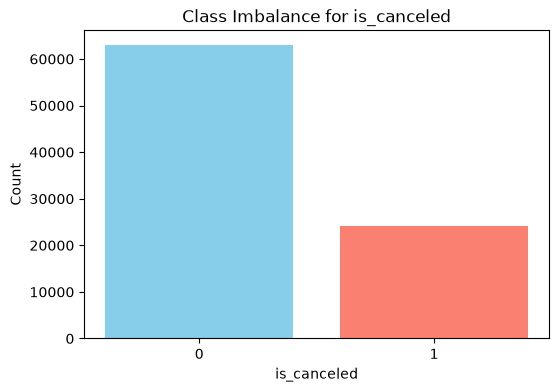

In [45]:
# visualise the class imbalance
plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts.values, color=['skyblue', 'salmon'])
plt.xticks(target_counts.index.astype(str))
plt.xlabel('is_canceled')
plt.ylabel('Count')
plt.title('Class Imbalance for is_canceled')

The target is moderately imbalanced: 62,963 bookings (72.3%) are completed stays, while 24,151 (27.7%) are cancellations or non-arrivals, giving a majority-to-minority ratio of approximately 2.6:1. Accuracy alone may therefore be misleading because a model predicting only the majority class would achieve 72.3% accuracy without identifying any cancellations or non-arrivals.

In [46]:
# audit leakage risk for the target variable
## check for any numeric columns that are perfectly correlated with the target variable
num_cols = [c for c in hotel_df.select_dtypes(include='number').columns if c != 'is_canceled']
numeric_corr = hotel_df[num_cols].corrwith(hotel_df['is_canceled']).abs().sort_values(ascending=False)
print('numeric correlation with is_canceled (abs), top 5:')
print(numeric_corr.head())

## categorical columns using cramer's v approach
cat_cols = hotel_df.select_dtypes(include='string').columns.tolist()
cat_association = pd.Series({
    col: association(pd.crosstab(hotel_df[col], hotel_df['is_canceled']), method='cramer')
    for col in cat_cols
}).sort_values(ascending=False)
print()
print("categorical association with is_canceled (Cramer's V), top 5:")
print(cat_association.head())

numeric correlation with is_canceled (abs), top 5:
required_car_parking_spaces    0.184781
lead_time                      0.167538
total_of_special_requests      0.125205
adr                            0.116673
booking_changes                0.094909
dtype: float64

categorical association with is_canceled (Cramer's V), top 5:
reservation_status         1.000000
reservation_status_date    0.326417
market_segment             0.218412
country                    0.199628
deposit_type               0.184779
dtype: float64


**No numeric leakage.** The strongest numeric correlation with `is_canceled` is `required_car_parking_spaces` at 0.18, which is weak and not a deterministic match. No numeric columns are dropped.

**Two categorical columns are leaking, and both should be removed since these are post-decision-point**
- **`reservation_status`: Cramer's V = 1.000, indicating a perfect, deterministic match.** It's a direct re-encoding of the target (`Check-Out` &#8594; 0, `Canceled`/`No-Show` &#8594; 1)
- **`reservation_status_date`: Cramer's V = 0.326** a moderate, and more importantly *structural*: it's the date the booking's final status was set, which by definition isn't known until after that outcome happens.

**Decision:** both `reservation_status` and `reservation_status_date` must be excluded from Assignment 2's feature set as they are post-decision-point variables that would leak information about the target variable `is_canceled`.

In [47]:
before_summary = f'shape of the dataset: {hotel_df.shape}'

hotel_df = hotel_df.drop(columns=['reservation_status', 'reservation_status_date'])

after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue=f'reservation_status and reservation_status_date are post-decision-point leakage: Cramer\'s V = {cat_association["reservation_status"]:.3f} (a deterministic re-encoding of is_canceled) and {cat_association["reservation_status_date"]:.3f} respectively -- neither could be known at booking confirmation, only after the outcome.',
    evidence=before_summary,
    action='Dropped the reservation_status and reservation_status_date columns.',
    justification='Keeping either column risks it being used as a predictive feature in Assignment 2, which would trivially "solve" cancellation prediction using the outcome itself. Removing them now, rather than just documenting the risk, makes the leak impossible to reintroduce by accident downstream.',
    before=before_summary,
    after=after_summary,
)

In [48]:
NOT_AVAILABLE_AT_BOOKING = {
    'assigned_room_type', # only known at/near check-in, not at booking time
    'booking_changes', # cumulative count as of data extraction, not at booking time
    'days_in_waiting_list' # accrues after booking, not known at booking time
}

before_summary = f'shape of the dataset: {hotel_df.shape}'

leak_cols = [col for col in NOT_AVAILABLE_AT_BOOKING if col in hotel_df.columns]
hotel_df = hotel_df.drop(columns=leak_cols)

after_summary = f'shape of the dataset: {hotel_df.shape}'

log_preprocessing(
    issue='assigned_room_type, booking_changes, and days_in_waiting_list are only known at or after booking confirmation, not at the decision-time point Section 1 defines for Assignment 2 features.',
    evidence="Not available at booking time, so they are invalid predictive features for the target variable is_canceled. ",
    action=f'Dropped {leak_cols} from the dataset.',
    justification='Consistent with the decision-time point defined in Section 1: a column knowable only after booking confirmation is an invalid predictive feature',
    before=before_summary,
    after=after_summary,
)


### 2.7 Feature Engineering

Three features are derived row by row from existing columns. None of them uses `is_canceled` or any statistic learned from the data, so they are safe to create before the train/test split in `02_modelling_evaluation.ipynb`.

- **`booked_via_agent` / `booked_via_company`:** `agent` and `company` are nominal IDs with over 300 levels each, and most IDs cover very few bookings. Whether an agent or company was involved (0 = not involved, see 2.1.3) is a stable booking characteristic the stakeholder can act on; which specific partner it was is not.
- **`country_group`:** `country` has 178 levels. `PRT` alone covers about a third of bookings and every other country is far smaller, so it is grouped into `PRT`, `Other` and `Unknown` (the explicit missing category from 2.1.4). This also limits how finely the model can treat guests by nationality.

The raw `agent`, `company` and `country` columns are kept in the cleaned CSV for traceability; `02_modelling_evaluation.ipynb` decides which columns are used as features.

In [49]:
before_summary = f'shape of the dataset: {hotel_df.shape}'

hotel_df['booked_via_agent'] = (hotel_df['agent'] != 0).astype('Int64')
hotel_df['booked_via_company'] = (hotel_df['company'] != 0).astype('Int64')
hotel_df['country_group'] = hotel_df['country'].where(hotel_df['country'].isin(['PRT', 'Unknown']), 'Other')

after_summary = f'shape of the dataset: {hotel_df.shape}'

country_share = hotel_df['country'].value_counts(normalize=True) * 100
print(f"booked_via_agent: {hotel_df['booked_via_agent'].mean():.1%} of bookings; booked_via_company: {hotel_df['booked_via_company'].mean():.1%}")
print(hotel_df['country_group'].value_counts())

log_preprocessing(
    issue=f"agent ({hotel_df['agent'].nunique()} levels), company ({hotel_df['company'].nunique()} levels) and country ({hotel_df['country'].nunique()} levels) are high-cardinality nominal columns that would create many sparse, hard-to-interpret features.",
    evidence=f"PRT covers {country_share['PRT']:.1f}% of bookings; the next largest country covers {country_share.drop(['PRT']).iloc[0]:.1f}%.",
    action='Added booked_via_agent and booked_via_company (1 if an agent/company was involved) and country_group (PRT / Other / Unknown). Raw columns kept for traceability.',
    justification='Row-wise rules that do not use the target, so safe before the split. Involvement and a coarse origin group are stable, interpretable booking characteristics; individual partner IDs and nationalities are fragile and raise fairness concerns.',
    before=before_summary,
    after=after_summary,
)

booked_via_agent: 85.9% of bookings; booked_via_company: 6.0%
country_group
Other      59073
PRT        27465
Unknown      576
Name: count, dtype: Int64


### 2.8 Summary of Cleaning Actions

In [50]:
# display the updated cleaning log
display(
    pd.DataFrame(cleaning_log).style.set_properties(**{
        'text-align': 'left',
        'white-space': 'pre-line',
        'vertical-align': 'top',
    })
)

,issue,evidence,action,justification,before,after
0,Missing-value representation is inconsistent and integer columns are stored as float64,"Raw dtypes: 16 int64 12 str 4 float64 shape of the dataset: (119987, 32)",Converted all columns to pandas nullable dtypes (Int64/Float64/string) so every missing value is represented consistently as pandas.NA.,"convert_dtypes() infers nullable Int64/Float64/string dtypes from the actual values, recovering integer columns pd.read_csv() only cast to float64 because they contain missing values, and unifying every missing value to pandas.NA.","16 int64 12 str 4 float64 shape of the dataset: (119987, 32)","19 Int64 12 string 1 Float64 shape of the dataset: (119987, 32)"
1,"agent and company are missing for a large share of rows (agent 13.79%, company 94.31%); a missing value most plausibly means ""no agent/company was involved in this booking"" rather than an unrecorded value.","Before: 16541 missing agent 113162 missing company shape of the dataset: (119987, 32) Neither column contains a 0, negative, or non-integer value that could already represent ""no agent/company"" (agent range 1-535, company range 6-543).","Imputed the missing company and agent values with 0 to represent ""not involved"".","Treating missing agent/company as a genuine ""not involved"" category preserves its cancellation-risk signal rather than discarding it via row deletion or mode imputation. 0 is a safe placeholder since it does not collide with any real agent/company ID.","16541 missing agent 113162 missing company shape of the dataset: (119987, 32)","0 missing agent 0 missing company shape of the dataset: (119987, 32)"
2,"Missing values in country cluster around a specific booking profile and a much lower cancellation rate, rather than being spread evenly.","The 628 NA-country rows are mostly Resort Hotel, Corporate, and Direct bookings rather than the travel-agent channels that dominate the rest of the dataset. Cancellation rate 19.75% missing vs. 37.14% present (chi-squared = 80.26, p = 3.3e-19).","Recoded the missing country values to an explicit ""Unknown"" category.","Since the missingness itself carries a real signal tied to booking channel and cancellation risk, mode-imputing (which would fabricate a nationality) or dropping the rows (which would discard that low-cancellation segment) would both distort the dataset. Keeping it as an explicit category preserves the pattern as a usable feature, at negligible cost given the small missingness rate (0.52%).","628 missing country shape of the dataset: (119987, 32)","0 missing country shape of the dataset: (119987, 32)"
3,children is missing for 182 rows (0.15%) and the true value cannot be recovered.,"Cancellation rate 35.16% missing vs. 37.05% present (chi-squared = 0.20, p = 0.65).",Dropped the 182 rows with missing children.,"The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Imputing 0 would assume the booking had no children, which the data cannot confirm. The cost is 0.15% of rows.","182 missing children shape of the dataset: (119987, 32)","0 missing children shape of the dataset: (119805, 32)"
4,customer_type is missing for 154 rows (0.13%) and the true value cannot be recovered.,"Cancellation rate 38.96% missing vs. 37.04% present (chi-squared = 0.17, p = 0.68).",Dropped the 154 rows with missing customer_type.,"The missingness shows no significant link to the outcome, so dropping these rows should not bias the data. Mode imputation would assign a customer type the data cannot confirm, and an ""Unknown"" category would preserve no signal. The cost is 0.13% of rows.","154 missing customer_type shape of the dataset: (119805, 32)","0 missing customer_type shape of the dataset: (119651, 32)"
5,distribution_channel is missing for 164 rows (0.14%) and the true value cannot be recovered.,"Cancellation rate 41.46% missing vs. 37.04% present (chi-squared = 1.19, p = 0.27).",Dropped the 164 rows with missing distr

In [51]:
# save cleaned dataset to a new CSV file
hotel_df.to_csv(OUTPUT_PATH, index=False)
print(f"Cleaned dataset saved to {OUTPUT_PATH}")

Cleaned dataset saved to data/hotel_bookings_cleaned.csv


## 3. Data Dictionary

The 30 variables below are the ones retained in `hotel_bookings_cleaned.csv`. Type uses the nominal/ordinal/interval/ratio classification; the treatment column cross-references the section that logged each cleaning step. 5 variables audited in 2.6 were removed for target leakage / decision-time violation.

| Variable | Type | Units | Meaning | Cleaning treatment |
|---|---|---|---|---|
| `hotel` | cat (nom) | -- | Hotel type (City Hotel / Resort Hotel) | `CityHotel`/`ResortHotel` typos fixed (2.4) |
| `is_canceled` | cat (nom) | -- | **Target.** 1 = `Canceled` or `No-Show`, 0 = `Check-Out` | none |
| `lead_time` | num (ratio) | days | Days between booking and arrival | none |
| `arrival_date_year` | num (int) | year | Arrival year (2015-2017) | none |
| `arrival_date_month` | cat (ord) | -- | Arrival month name | none |
| `arrival_date_week_number` | num (int) | week | Arrival week number as recorded in the source (does not follow ISO weeks) | none |
| `arrival_date_day_of_month` | num (int) | day | Arrival day of month | none |
| `stays_in_weekend_nights` | num (ratio) | nights | Sat/Sun nights booked | none |
| `stays_in_week_nights` | num (ratio) | nights | Mon-Fri nights booked | none |
| `adults` | num (ratio) | count | Number of adults | 165 zero-guest rows dropped and 218 zero-adult rows excluded as a scope restriction (2.3); large group counts (up to 55) kept (2.5) |
| `children` | num (ratio) | count | Number of children | 182 NA rows dropped (2.1.5); 1 extreme value (10) kept (2.5) |
| `babies` | num (ratio) | count | Number of babies | none; 2 extreme values (9, 10) kept (2.5) |
| `meal` | cat (ord) | -- | Meal plan (BB/HB/FB/SC/Undefined) | 138 NA rows dropped (2.1.9); case/whitespace normalised (2.4) |
| `country` | cat (nom) | -- | Guest country (ISO code) | 628 NA recoded to `Unknown` (2.1.4) |
| `market_segment` | cat (nom) | -- | Booking market segment | 129 NA rows dropped (2.1.8); case/whitespace + `Direc` typo fixed (2.4) |
| `distribution_channel` | cat (nom) | -- | Booking distribution channel | 164 NA rows dropped (2.1.7); case/whitespace normalised (2.4) |
| `is_repeated_guest` | cat (nom, binary) | -- | 1 if guest stayed before | none |
| `previous_cancellations` | num (ratio) | count | Prior cancellations by this guest | none |
| `previous_bookings_not_canceled` | num (ratio) | count | Prior completed bookings by this guest | none |
| `reserved_room_type` | cat (nom) | -- | Room type reserved (coded) | none |
| `deposit_type` | cat (nom) | -- | No Deposit / Non Refund / Refundable | none |
| `agent` | cat (nom, numeric ID) | -- | Booking agent ID; 0 = no agent | 16,541 NA imputed to 0 "not involved" (2.1.3) |
| `company` | cat (nom, numeric ID) | -- | Booking company ID; 0 = no company | 113,162 NA imputed to 0 "not involved" (2.1.3) |
| `customer_type` | cat (nom) | -- | Transient / Transient-Party / Contract / Group | 154 NA rows dropped (2.1.6); case/whitespace normalised (2.4) |
| `adr` | num (ratio) | price/night | Average daily rate | 1 negative row dropped (2.3); 5,400 outlier flagged, kept (2.5) |
| `required_car_parking_spaces` | num (ratio) | count | Parking spaces requested | none |
| `total_of_special_requests` | num (ratio) | count | Count of special requests | none |
| `booked_via_agent` | cat (nom, binary, engineered) | -- | 1 if an agent was involved in the booking | derived in 2.7 from `agent` |
| `booked_via_company` | cat (nom, binary, engineered) | -- | 1 if a company was involved in the booking | derived in 2.7 from `company` |
| `country_group` | cat (nom, engineered) | -- | `PRT` / `Other` / `Unknown` | derived in 2.7 from `country` |